# Lecture 17: Adaptive timesteps and sympletic integrators

Runge-Kutta is a fine integrator for most ordinary differential equations, but for orbits, it runs into a a crucial setback that it does not conserve energy. In this lecture, we will discuss some integrators that help mitigate this problem by introducing adaptive timesteps. We will also introduce the concept of a symplectic integrator, which conserves the energy of the orbit every timestep. This property is crucial to integrate the behavior of orbits over many millions of orbits.

**Include links and typical things here**

This lecture made use of the following material:



In [1]:
# Nice things to have this lecture
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

Adaptive Timesteps
==================

So far we've been integrating with a fixed timestep.  This gives us no real control over the error.  What we would like to do is take a small timestep when the solution is changing fast, and a larger timestep when the solution changes more slowly.

To do this, we need to be able to assess the error in our solution as we integrate.  There are lots of different
ways to do this in the literature (see, e.g., the [Wikipedia article on adaptive stepping](https://en.wikipedia.org/wiki/Adaptive_step_size)):

* Take two half steps and compare to one full step
* Compare higher and lower order methods (sometimes the lower order method is _embedded_ in the higher-order  method,
  for instance this is the [RK45 method used by SciPy](https://en.wikipedia.org/wiki/Dormand%E2%80%93Prince_method))

We'll do the first method here, as it is the simplest.  


Consider integrating
a function $y(t)$ through some timestep $\tau$:

![adaptive timestep comparing 2 dt/2 steps to a single dt step](https://zingale.github.io/computational_astrophysics/_images/adaptive_timestep.png)

The top evolution takes a single step of size $\tau$ while the bottom takes
two steps each of $\tau/2$.  These two integrations both end at $y(t+\tau)$,
but we expect the one that took 2 half steps to be more accurate (since the truncation error is smaller).

Now, we know that RK4 is _locally_ 5th order accurate, so that means that
for our single step, the error will be:

$$\epsilon \sim \tau^5$$

And imagine that we wanted to achieve an error of $\epsilon_\mathrm{want}$&mdash;
there is a timestep $\tau$ that would get this:

$$\epsilon_\mathrm{want} \sim \tau_\mathrm{est}^5$$

If we take the ratio of these, then any proportionality cancels, and we have

$$\tau_\mathrm{est} = \tau \left (\frac{\epsilon_\mathrm{want}}{\epsilon} \right)^{1/5}$$

**Note:**
If we were not accurate enough, this would predict a finer timestep that would
give us our desired accuracy.  And if we were too accurate, then this would
tell us how much we could increase the timestep while maintaining our desired
accuracy.

Let's consider doing this with RK4.  Our approach will be:

1. Integrate from $y(t)$ to $y(t+\tau)$ using a single timestep, $\tau$. Call the solution $y^\mathrm{single}$
   
2. Integrate from $y(t)$ to $y(t+\tau)$ using two steps of size $\tau/2$. Call the solution $y^\mathrm{double}$
   
3. Compute an estimate of the _relative error_ in the solution as:
   $$\epsilon_\mathrm{rel} = \left | \frac{y^\mathrm{double} - y^\mathrm{single}}{y^\mathrm{double}} \right |$$
   
5. Compute the timestep that would give us our desired accuracy, $\epsilon_\mathrm{want}$:

   $$\tau_\mathrm{est} = \tau \left (\frac{\epsilon_\mathrm{want}}{\epsilon_\mathrm{rel}} \right)^{1/5}$$

6. If $\epsilon_\mathrm{rel} < \epsilon_\mathrm{want}$ then our timestep
   was good, and store the solution at time $t + \tau$ as $y^\mathrm{double}$.
   Increase the timestep according to $\tau_\mathrm{est}$ for the next step.
   If $\epsilon_\mathrm{rel} > \epsilon_\mathrm{want}$ then throw away our
   solution and go back to $y(t)$ and retry the integration with the new, smaller
   $\tau_\mathrm{est}$.
   
In practice, we usually limit the amount that the timestep can change from one
attempt to the next by a factor of $\sim 2$ or so.

**Note:**
For a different method, the timestep estimate will likely be different, since
it depends on the scaling of the local truncation error with the timestep, $\tau$.

# Adaptive RK4 Orbits

We'll use the same basic ideas in our fixed timestep RK4 integrator.

In [2]:
# global parameters
GM = 4.0 * np.pi**2  # assuming M = 1 solar mass

## `OrbitState`

The `OrbitState` class is unchanged.

In [3]:
class OrbitState:
    # a container to hold the star positions
    def __init__(self, x, y, u, v):
        self.x = x
        self.y = y
        self.u = u
        self.v = v

    def __add__(self, other):
        return OrbitState(self.x + other.x, self.y + other.y,
                          self.u + other.u, self.v + other.v)

    def __sub__(self, other):
        return OrbitState(self.x - other.x, self.y - other.y,
                          self.u - other.u, self.v - other.v)

    def __mul__(self, other):
        return OrbitState(other * self.x, other * self.y,
                          other * self.u, other * self.v)

    def __rmul__(self, other):
        return self.__mul__(other)

    def __str__(self):
        return f"{self.x:10.6f} {self.y:10.6f} {self.u:10.6f} {self.v:10.6f}"

## Integrator class

We'll put all of the logical for the integration and stepsize control into a class, called `OrbitsRK4`.
The main Runge-Kutta algorithm that we already explored is now in a function `single_step()`.

In [4]:
class OrbitsRK4:
    """ model the evolution of a single planet around the Sun"""

    def __init__(self, a, e):
        """ a = semi-major axis (in AU),
            e = eccentricity """

        self.a = a
        self.e = e

        x0 = 0.0          # start at x = 0 by definition
        y0 = a*(1.0 - e)  # start at perihelion

        # perihelion velocity (see C&O Eq. 2.33 for ex)
        u0 = -np.sqrt( (GM/a)* (1.0 + e) / (1.0 - e) )
        v0 = 0.0

        self.history = [OrbitState(x0, y0, u0, v0)]
        self.time = [0.0]

        self.n_reset = None

    def kepler_period(self):
        """ return the period of the orbit in yr """
        return np.sqrt(self.a**3)

    def energy(self, n):
        """ return the energy (per unit mass) at time n """

        state = self.history[n]
        return 0.5 * (state.u**2 + state.v**2) - \
            GM / np.sqrt(state.x**2 + state.y**2)

    def rhs(self, state):
        """ RHS of the equations of motion."""

        # current radius
        r = np.sqrt(state.x**2 + state.y**2)

        # position
        xdot = state.u
        ydot = state.v

        # velocity
        udot = -GM * state.x / r**3
        vdot = -GM * state.y / r**3

        return OrbitState(xdot, ydot, udot, vdot)

    def single_step(self, state_old, dt):
        """ take a single RK-4 timestep from t to t+dt for the system
        ydot = rhs """

        # get the RHS at several points
        ydot1 = self.rhs(state_old)

        state_tmp = state_old + 0.5 * dt * ydot1
        ydot2 = self.rhs(state_tmp)

        state_tmp = state_old + 0.5 * dt * ydot2
        ydot3 = self.rhs(state_tmp)

        state_tmp = state_old + dt * ydot3
        ydot4 = self.rhs(state_tmp)

        # advance
        state_new = state_old + (dt / 6.0) * (ydot1 + 2.0 * ydot2 +
                                              2.0 * ydot3 + ydot4)

        return state_new

    def integrate(self, dt_in, err, tmax):
        """ integrate the equations of motion using 4th order R-K method with an
            adaptive stepsize, to try to achieve the relative error err.  dt
            here is the initial timestep
            """
        
        # start with the old timestep
        dt_new = dt_in
        dt = dt_in

        n_reset = 0
        t = 0

        while t < tmax:
            
            state_old = self.history[-1]

            if err > 0.0:

                # adaptive stepping iteration loop -- keep trying to take a step
                # until we achieve our desired error

                rel_error = 1.e10

                n_try = 0
                while rel_error > err:
                    dt = min(dt_new, tmax-t)

                    # take 2 half steps
                    state_tmp = self.single_step(state_old, 0.5*dt)
                    state_new = self.single_step(state_tmp, 0.5*dt)

                    # now take just a single step to cover dt
                    state_single = self.single_step(state_old, dt)

                    # state_new should be more accurate than state_single since it
                    # used smaller steps

                    # estimate the relative error now
                    dstate = state_new - state_single

                    rel_error = max(abs(dstate.x / state_single.x),
                                    abs(dstate.y / state_single.y),
                                    abs(dstate.u / state_single.u),
                                    abs(dstate.v / state_single.v))

                    # adaptive timestep algorithm for RK4

                    dt_est = dt * abs(err/rel_error)**0.2

                    # give a little safety in our dt_est, and limit the
                    # amount the timestep can change 
                    dt_new = min(max(0.9 * dt_est, 0.25 * dt), 4.0 * dt)

                    n_try += 1

                if n_try > 1:
                    # n_try = 1 if we took only a single try at the step
                    n_reset += (n_try-1)

            else:

                # take just a single step
                dt = min(dt_new, tmax-t)

                # take just a single step to cover dt
                state_new = self.single_step(state_old, dt)

            # successful step
            t += dt

            # store
            self.time.append(t)
            self.history.append(state_new)

        self.n_reset = n_reset

    def plot(self, points=False):
        """plot the orbit"""
        fig, ax = plt.subplots()
        x = [q.x for q in self.history]
        y = [q.y for q in self.history]

        # draw the Sun
        ax.scatter([0], [0], marker=(20, 1), color="y", s=250)

        if points:
            ax.scatter(x, y, marker=".")
        else:
            ax.plot(x, y)
        ax.set_aspect("equal")
        return fig

## Highly eccentric orbit

Let's create an orbit with a tolerance of $10^{-5}$, and the a very high eccentricity ($a = 1$, $e = 0.95$)

In [5]:
o = OrbitsRK4(1.0, 0.95)
o.integrate(0.05, 1.e-5, o.kepler_period())

How many points did it take?

In [6]:
len(o.history)

92

and how many times did we reset?

In [7]:
o.n_reset

39

Let's plot it

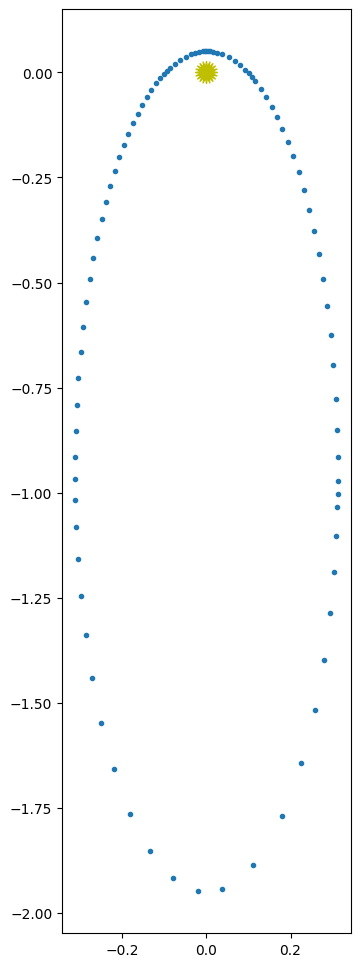

In [10]:
fig = o.plot(points=True)
fig.set_size_inches(5, 12)
plt.show()

Clearly we see that the size of the timestep is much larger at aphelion as compared to perihelion.

Let's create a version with a fixed timestep, with a timestep of $0.001~\mathrm{yr}$.  We can do this by passing in a negative error.

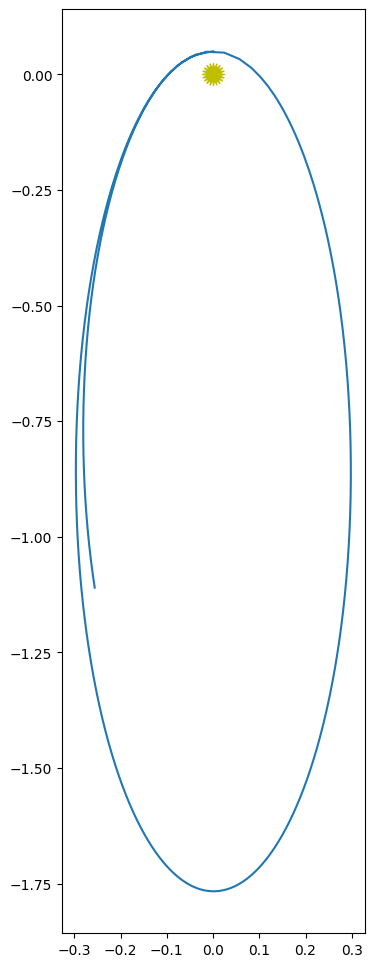

In [11]:
o_fixed = OrbitsRK4(1.0, 0.95)
o_fixed.integrate(0.001, -1, o_fixed.kepler_period())
fig = o_fixed.plot()
fig.set_size_inches(5, 12)
plt.show()

In [12]:
len(o_fixed.history)

1001

We need a really small fixed step size to integrate this at all reasonably

## Timestep evolution

Let's look at the adaptive version some more.  First, let's look at the timestep evolution.

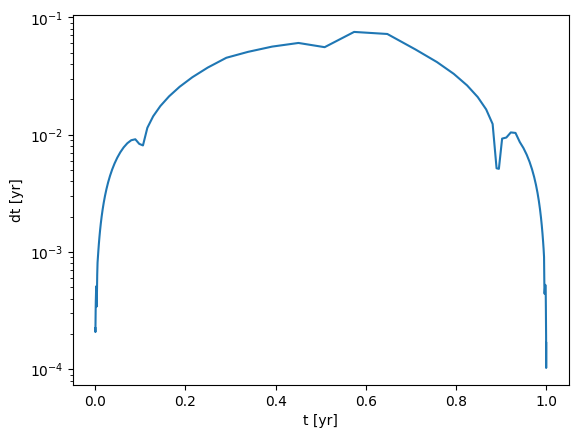

In [15]:
ts = np.array(o.time)

dt = ts[1:] - ts[:-1]
tc = 0.5 * (ts[1:] + ts[:-1])

fig, ax = plt.subplots()
ax.plot(tc, dt)
ax.set_xlabel("t [yr]")
ax.set_ylabel("dt [yr]")
ax.set_yscale("log")
plt.show()

Notice that the timestep changes by ~ 3 orders of magnitude over the evolution.

## Energy conservation

What about energy conservation?

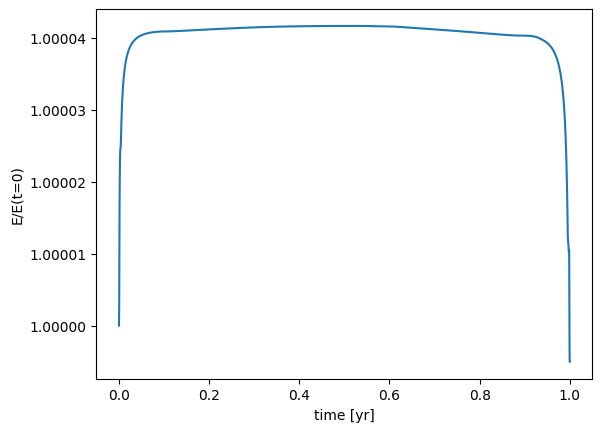

In [16]:
e = []
ts = o.time
for n in range(len(o.history)):
    e.append(o.energy(n))
    
fig, ax = plt.subplots()
ax.plot(ts, e/e[0])
ax.set_xlabel("time [yr]")
ax.set_ylabel("E/E(t=0)")
ax.ticklabel_format(useOffset=False)
plt.show()

Now let's do 10 orbits

In [17]:
o = OrbitsRK4(1.0, 0.95)
o.integrate(0.05, 1.e-5, 20*o.kepler_period())

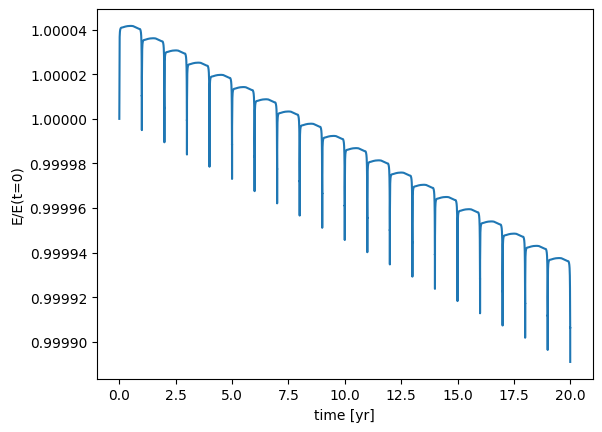

In [18]:
e = []
ts = o.time
for n in range(len(o.history)):
    e.append(o.energy(n))
    
fig, ax = plt.subplots()
ax.plot(ts, e/e[0])
ax.set_xlabel("time [yr]")
ax.set_ylabel("E/E(t=0)")
ax.ticklabel_format(useOffset=False)
plt.show()

**Caution:** We can see that RK4 does not conserve energy!

There is a steady decrease in the total energy over 20 orbits.  If we wanted to evolve for millions of years, this would certainly be a problem.  Making the tolerance tighter certainly will help, but it will also make things a lot more expensive.

The problem is that 4th order Runge-Kutta does not know anything about energy conservation.

# ODEs and Conservation

As we saw now in a few examples, the Runge-Kutta methods do not conserve energy.  For integrating over very long timescales, this can be problematic.

Let's explore some other methods to get a feel for what it means to be conservative.

## Euler-Cromer method

The [Euler-Cromer method](https://en.wikipedia.org/wiki/Semi-implicit_Euler_method) or semi-implicit Euler method
is a first order method very similar to the first-order Euler, but with one simple change.  The update is:

$${\bf v}^{n+1} = {\bf v}^n + \tau \,{\bf a}({\bf r}^{n}) + \mathcal{O}(\tau^2)$$

$${\bf r}^{n+1} = {\bf r}^n + \tau \, {\color{red}{\bf v}^{n+1}} + \mathcal{O}(\tau^2)$$

**Note:**
The only change is that we use the updated velocity, ${\bf v}^{n+1}$ in the expression to get the new position.  This is not an _implicit method_, since we already have the new velocity from the first expression.

## Implementation

Let's integrate our planet and compare this to the original Euler method.

We'll use the same core functions, included in the cell below (state is the OrbitState class above):

In [19]:
def rhs(state):
    """ RHS of the equations of motion."""

    # current radius
    r = np.sqrt(state.x**2 + state.y**2)

    # position
    xdot = state.u
    ydot = state.v

    # velocity
    udot = -GM * state.x / r**3
    vdot = -GM * state.y / r**3

    return OrbitState(xdot, ydot, udot, vdot)

def initial_conditions():
    x0 = 0
    y0 = 1
    u0 = -np.sqrt(GM / y0)
    v0 = 0

    return OrbitState(x0, y0, u0, v0)

def plot_func(history, ax=None, label=None):
    """make a plot of the solution.  If ax is None we setup a figure
    and make the entire plot returning the figure object, otherwise, we
    just append the plot to a current axis"""

    fig = None

    if ax is None:
        fig = plt.figure()
        ax = fig.add_subplot(111)

        # draw the Sun
        ax.scatter([0], [0], marker=(20,1), color="y", s=250)

    # draw the orbit
    xs = [q.x for q in history]
    ys = [q.y for q in history]

    ax.plot(xs, ys, label=label)

    if fig is not None:
        ax.set_aspect("equal")
        ax.set_xlabel("x [AU]")
        ax.set_ylabel("y [AU]")

    return fig

def error_radius(history):

    # define the error to be distance from (0, 0) at end compared to start
    R_orig = np.sqrt(history[0].x**2 + history[0].y**2)
    R_new = np.sqrt(history[-1].x**2 + history[-1].y**2)
    e = np.abs(R_new - R_orig)

    return e

def error_position(history):
    """return the difference in the distance from the Sun"""
    dx = history[0].x - history[-1].x
    dy = history[0].y - history[-1].y
    return np.sqrt(dx**2 + dy**2)

Here's the original Euler method

In [23]:
def euler_orbit(state0, tau, T):
    """integrate an orbit given an initial position, pos0, and velocity, vel0,
    using first-order Euler integration"""
    
    times = []
    history = []
    
    # initialize time
    t = 0
    
    # store the initial conditions
    times.append(t)
    history.append(state0)
    
    # main timestep loop
    while t < T:
        
        state_old = history[-1]
        
        # make sure that the last step does not take us past T
        if t + tau > T:
            tau = T - t

        # get the RHS
        ydot = rhs(state_old)
        
        # do the Euler update
        state_new = state_old + tau * ydot
        t += tau
        
        # store the state
        times.append(t)
        history.append(state_new)
        
    return times, history

and here's Euler-Cromer

In [26]:
def euler_cromer_orbit(state0, tau, T):
    """integrate an orbit given an initial position, pos0, and velocity, vel0,
    using first-order Euler-Cromer integration"""
    
    times = []
    history = []
    
    # initialize time
    t = 0
    
    # store the initial conditions
    times.append(t)
    history.append(state0)
    
    # main timestep loop
    while t < T:
        
        state_old = history[-1]
        
        # make sure that the last step does not take us past T
        if t + tau > T:
            tau = T - t

        # get the RHS
        ydot = rhs(state_old)
        
        # do the Euler update
        unew = state_old.u + tau * ydot.u
        vnew = state_old.v + tau * ydot.v
        
        xnew = state_old.x + tau * unew
        ynew = state_old.y + tau * vnew        

        state_new = OrbitState(xnew, ynew, unew, vnew)
        t += tau
        
        # store the state
        times.append(t)
        history.append(state_new)
        
    return times, history

In [27]:
state0 = initial_conditions()

tau = 0.01
tmax = 1.0

times_euler, history_euler = euler_orbit(state0, tau, tmax)
times_ec, history_ec = euler_cromer_orbit(state0, tau, tmax)

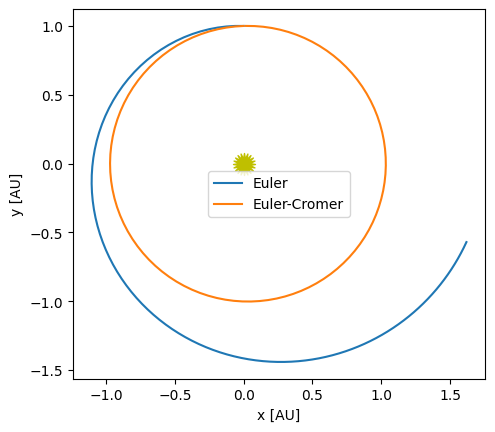

In [28]:
fig = plot_func(history_euler, label="Euler")
plot_func(history_ec, ax=fig.gca(), label="Euler-Cromer")
fig.gca().legend()
plt.show()

These are both first-order accurate, but notice how much better the Euler-Cromer solution is!

## Angular momentum

Let's consider the angular momentum of the orbit as evolved by Euler-Cromer.

Angular momentum / unit mass in the orbit plane is:

$$l = |{\bf v} \times {\bf r} | = uy - vx$$

Using the Euler-Cromer evolution:

$${\bf v}^{n+1} = {\bf v}^n + \tau {\bf a}({\bf r}^n)$$

$${\bf r}^{n+1} = {\bf r}^n + \tau {\bf v}^{n+1}$$

We can compute the new angular momentum

$$l^{n+1} = u^{n+1} y^{n+1} - v^{n+1} x^{n+1}
 = \underbrace{u^n y^n - v^n x^n}_{\mbox{this is}~ l^n} + \tau \underbrace{(a_{(x)}^n y^n - a_{(y)}^n x^n)}_{\mbox{this is}~{\bf a}\times {\bf r} = 0} + \mathcal{O}(\tau^2)$$
 
We see that, for a central potential, since ${\bf a} \times {\bf r} = 0$, the new (discrete) angular momentum is equal to the old angular momentum in this scheme (to $\mathcal{O}(\tau^2)$).

So the Euler-Cromer method does better because it has a notion of conservation.

Note that there is still error, and it will converge globally first order.

## Eccentric orbit

Let's look at an eccentric orbit:

In [30]:
a = 1.0
e = 0.6

# perihelion velocity
x0 = 0.0          # start at x = 0 by definition
y0 = a * (1.0 - e)  # start at perihelion

u0 = -np.sqrt((GM/a)* (1.0 + e) / (1.0 - e))
v0 = 0.0

state0 = OrbitState(x0, y0, u0, v0)

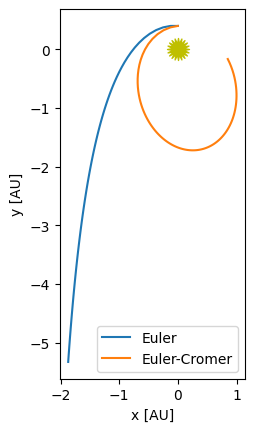

In [31]:
times_euler, history_euler = euler_orbit(state0, tau, tmax)
times_ec, history_ec = euler_cromer_orbit(state0, tau, tmax)

fig = plot_func(history_euler, label="Euler")
plot_func(history_ec, ax=fig.gca(), label="Euler-Cromer")
fig.gca().legend()
plt.show()

# Time Symmetric Integration

Let's look at what happens to our Euler-Cromer integration if we integrate backwards in time.  For our orbit, this would basically mean instead of orbiting counterclockwise it would orbit clockwise.

Start with the Euler-Cromer method:


$${\bf v}^{n+1} = {\bf v}^n + \tau \,{\bf a}({\bf r}^{n})$$

$${\bf r}^{n+1} = {\bf r}^n + \tau \,{\bf v}^{n+1}$$

To integrate backwards in time, we change:

* $\tau \rightarrow -\tau$
* $q^{n+1} \rightarrow q^{n-1}$ for any quantity $q$.

This gives us:

$${\bf v}^{n-1} = {\bf v}^n - \tau \,{\bf a}({\bf r}^{n})$$

$${\bf r}^{n-1} = {\bf r}^n - \tau \,{\bf v}^{n-1}$$

Rearranging, we have:

$${\bf v}^{n} = {\bf v}^{n-1} + \tau \,{\bf a}({\bf r}^{n})$$

$${\bf r}^{n} = {\bf r}^{n-1} +\tau \,{\bf v}^{n-1}$$

This kinda looks like the original Euler-Cromer method, except now the velocity update is implicit (the acceleration is at the "new time") while the position update is explicit.

## Velocity Verlet method/ Leapfrog integration

The symmetry we see when we look at the time-reversed Euler-Cromer suggests that if we do the two forms in succession, then we will be symmetric in time.  This means doing:

$${\bf v}^{n+1} = {\bf v}^n + \tau \,{\bf a}({\bf r}^{n})$$

$${\bf r}^{n+1} = {\bf r}^n + \tau \,{\bf v}^{n+1}$$

$${\bf r}^{n+2} = {\bf r}^{n+1} + \tau \,{\bf v}^{n+1}$$

$${\bf v}^{n+2} = {\bf v}^{n+1} + \tau \,{\bf a}({\bf r}^{n+2})$$

Notice that the middle 2 position updates use the same velocity, so we can combine them as:

$${\bf v}^{n+1} = {\bf v}^n + \tau \,{\bf a}({\bf r}^{n})$$

$${\bf r}^{n+2} = {\bf r}^n + 2 \tau \,{\bf v}^{n+1}$$

$${\bf v}^{n+2} = {\bf v}^{n+1} + \tau \,{\bf a}({\bf r}^{n+2})$$

This essentially means that we need to take 2 timesteps that are the same size, one after another.  We can instead take $\tau \rightarrow \tau / 2$ and we get:

$${\bf v}^{n+1/2} = {\bf v}^n + \frac{\tau}{2} \,{\bf a}({\bf r}^{n})$$

$${\bf r}^{n+1} = {\bf r}^n + \tau \,{\bf v}^{n+1/2}$$

$${\bf v}^{n+1} = {\bf v}^{n+1/2} + \frac{\tau}{2} \,{\bf a}({\bf r}^{n+1})$$

This is called the [_velocity Verlet method_](https://en.wikipedia.org/wiki/Verlet_integration#Velocity_Verlet) or the _kick-drift-kick_ method.  It is has time-reversal symmetry and is very popular with N-body integrators.  

**Note:**
An equivalent method is [leapfrog integration](https://en.wikipedia.org/wiki/Leapfrog_integration).  This is also a type
of [symplectic integration](https://en.wikipedia.org/wiki/Symplectic_integrator) which can be related to Hamilton's equations of motion. It is just derived a bit differently. 

It can be shown that this method is _locally third-order accurate_ and _globally second-order accurate_.

## Time-reversal and energy conservation

Imagine that our method has the property that when we integrate the system, the total energy decreases with time.

That means that if we were to integrate backwards in time, the total energy should increase.

However, if the method is symmetric in time, then the behavior of the energy has to be the same when integrating forward in time and backwards in time.

This means that energy is conserved in a time-symmetric method.

## Application to orbits

Let's apply these new methods to our orbit problems.  To make it interesting, we'll evolve for many periods.

We'll use a class below that implements everything in the same tidy package:

In [33]:
class Orbit:
    """ hold the initial conditions of a planet/comet/etc. orbiting
        the Sun and integrate """

    def __init__(self, a, e):
        """ a = semi-major axis (in AU),
            e = eccentricity """

        self.a = a
        self.e = e

        # perihelion velocity (see C&O Eq. 2.33 for ex)
        x0 = 0.0          # start at x = 0 by definition
        y0 = a * (1.0 - e)  # start at perihelion

        u0 = -np.sqrt((GM/a) * (1.0 + e) / (1.0 - e))
        v0 = 0.0

        self.state0 = OrbitState(x0, y0, u0, v0)

    def kepler_period(self):
        """ return the period of the orbit in yr """
        return np.sqrt(self.a**3)

    def rhs(self, state):
        """ RHS of the equations of motion."""

        # current radius
        r = np.sqrt(state.x**2 + state.y**2)

        # position
        xdot = state.u
        ydot = state.v

        # velocity
        udot = -GM * state.x / r**3
        vdot = -GM * state.y / r**3

        return OrbitState(xdot, ydot, udot, vdot)

    def int_euler(self, dt, tmax):
        """ integrate the equations of motion using Euler's method.
            We integrate until t = tmax """

        # initial conditions
        times = [0.0]
        history = [self.state0]

        t = 0.0

        while t < tmax:

            state_old = history[-1]

            dt = min(dt, tmax-t)

            # get the RHS
            ydot = self.rhs(state_old)

            # advance
            state_new = state_old + dt * ydot
            t += dt

            # store
            times.append(t)
            history.append(state_new)

        return times, history

    def int_euler_cromer(self, dt, tmax):
        """ integrate the equations of motion using the Euler-Cromer method.
            We integrate until t = tmax """

        # initial conditions
        times = [0.0]
        history = [self.state0]

        t = 0.0

        while t < tmax:

            state_old = history[-1]

            dt = min(dt, tmax-t)

            # get the RHS
            ydot = self.rhs(state_old)

            # do the Euler update
            unew = state_old.u + dt * ydot.u
            vnew = state_old.v + dt * ydot.v

            xnew = state_old.x + dt * unew
            ynew = state_old.y + dt * vnew

            state_new = OrbitState(xnew, ynew, unew, vnew)
            t += dt

            # store the state
            times.append(t)
            history.append(state_new)

        return times, history

    def int_rk2(self, dt, tmax):
        """ integrate the equations of motion using 2nd order R-K
            method (also know as the midpoint method) We integrate
            until we reach tmax """

        # initial conditions
        times = [0.0]
        history = [self.state0]

        t = 0.0

        while t < tmax:

            state_old = history[-1]

            dt = min(dt, tmax-t)

            # get the RHS
            ydot = self.rhs(state_old)

            # advance to dt/2 to get intermediate position
            state_tmp = state_old + 0.5 * dt * ydot

            # get the RHS with the intermediate state
            ydot = self.rhs(state_tmp)

            state_new = state_old + dt * ydot

            t += dt

            # store
            times.append(t)
            history.append(state_new)

        return times, history

    def int_velocity_verlet(self, dt, tmax):
        """ integrate the equations of motion using the Velocity Verlet
            method (which is a kick-drift-kick Leapfrog method) """

        # initial conditions
        times = [0.0]
        history = [self.state0]

        t = 0.0

        while t < tmax:

            state_old = history[-1]

            dt = min(dt, tmax-t)

            ydot_old = self.rhs(state_old)

            # kick
            uhalf = state_old.u + 0.5 * dt * ydot_old.u
            vhalf = state_old.v + 0.5 * dt * ydot_old.v

            # drift
            xnew = state_old.x + dt * uhalf
            ynew = state_old.y + dt * vhalf

            # kick
            # this works only because the acceleration does not depend
            # on velocity
            ydot_new = self.rhs(OrbitState(xnew, ynew, uhalf, vhalf))

            unew = uhalf + 0.5 * dt * ydot_new.u
            vnew = vhalf + 0.5 * dt * ydot_new.v

            state_new = OrbitState(xnew, ynew, unew, vnew)

            t += dt

            # store
            times.append(t)
            history.append(state_new)

        return times, history

    def int_rk4(self, dt, tmax):
        """ integrate the equations of motion using 4th order R-K
            method.  """

        # initial conditions
        times = [0.0]
        history = [self.state0]

        t = 0.0

        while t < tmax:

            state_old = history[-1]

            dt = min(dt, tmax-t)

            # get the RHS at several points
            ydot1 = self.rhs(state_old)

            state_tmp = state_old + 0.5 * dt * ydot1
            ydot2 = self.rhs(state_tmp)

            state_tmp = state_old + 0.5 * dt * ydot2
            ydot3 = self.rhs(state_tmp)

            state_tmp = state_old + dt * ydot3
            ydot4 = self.rhs(state_tmp)

            # advance
            state_new = state_old + (dt / 6.0) * (ydot1 + 2.0 * ydot2 +
                                                  2.0 * ydot3 + ydot4)
            t += dt

            # store
            times.append(t)
            history.append(state_new)

        return times, history

def energy(history):
    """return a vector of energy for all times"""
    E = [0.5 * (state.u**2 + state.v**2) - GM / np.sqrt(state.x**2 + state.y**2)
         for state in history]
    return E

In [35]:
o = Orbit(1.0, 0.3)
dt = 0.05
tmax = 50.0 * o.kepler_period()

In [36]:
t_euler, hist_euler = o.int_euler(dt, tmax)
t_ec, hist_ec = o.int_euler_cromer(dt, tmax)
t_rk2, hist_rk2 = o.int_rk2(dt, tmax)
t_rk4, hist_rk4 = o.int_rk4(dt, tmax)
t_vv, hist_vv = o.int_velocity_verlet(dt, tmax)

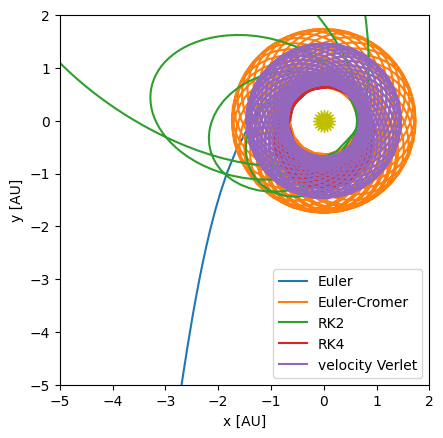

In [37]:
fig = plot_func(hist_euler, label="Euler")
plot_func(hist_ec, ax=fig.gca(), label="Euler-Cromer")
plot_func(hist_rk2, ax=fig.gca(), label="RK2")
plot_func(hist_rk4, ax=fig.gca(), label="RK4")
plot_func(hist_vv, ax=fig.gca(), label="velocity Verlet")
ax = fig.gca()
ax.legend()
ax.set_ylim(-5, 2)
ax.set_xlim(-5, 2)
plt.show()

Now let's look at the energy

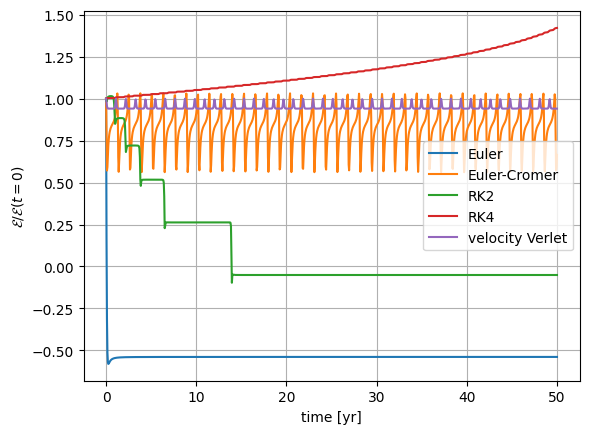

In [38]:
fig, ax = plt.subplots()

E_euler = energy(hist_euler)
ax.plot(t_euler, E_euler/E_euler[0], label="Euler")

E_ec = energy(hist_ec)
ax.plot(t_ec, E_ec/E_ec[0], label="Euler-Cromer")

E_rk2 = energy(hist_rk2)
ax.plot(t_rk2, E_rk2/E_rk2[0], label="RK2")

E_rk4 = energy(hist_rk4)
ax.plot(t_ec, E_rk4/E_rk4[0], label="RK4")

E_vv = energy(hist_vv)
ax.plot(t_vv, E_vv/E_vv[0], label="velocity Verlet")

ax.legend()
ax.grid()

ax.set_xlabel("time [yr]")
ax.set_ylabel(r"$\mathcal{E}/\mathcal{E}(t=0)$")
plt.show()

We see that Euler-Cromer and velocity-Verlet both conserve energy over a period, while the other methods have a drift in the total amount of energy over time.

## What about adaptive timestepping?

Unfortunately, velocity-Verlet loses its time-symmetry when you adapt the timestep.

[Hut et al. 1995](https://articles.adsabs.harvard.edu/pdf/1995ApJ...443L..93H) discuss this issue and how to restore time-symmetry into the method.  A nice overview is given in [Boekholt et al. 2022](https://arxiv.org/pdf/2212.09745.pdf).

## Higher-order Integrators

The paper [_Construction of higher order symplectic integrators_](https://ui.adsabs.harvard.edu/abs/1990PhLA..150..262Y/abstract) shows how to construct 4th and higher-order
symplectic integrators.

The [REBOUND library](https://rebound.readthedocs.io/en/latest/) provides a wide variety of integrators, symplectic and adaptive, that are used for few-body system
integration.